In [6]:
!pip -q install scipy statsmodels pandas matplotlib
from pathlib import Path
assert Path("/content/Burgmaier_Genotype_Phenotype_Replication - Burgmaier_S3_Source (2).csv").is_file(), "Upload Burgmaier CSV"
assert (Path("/content/NephVar Database - PKHD1 (6).csv").is_file() or Path("/content/NephVar Database - PKHD1 (5).csv").is_file()), "Upload NephVar CSV"

FOUR-CLASS POOLED PATIENTS
Eligible: 310
Valid RSA: 309
Flagged: 1


Cohort,Burgmaier,NephVar
Group,,
AA1–708,43,48
AA709–1837,51,62
AA1838–2624,22,21
AA2625–4074,21,41



PATIENT-LEVEL RSA DESCRIPTIVE STATISTICS


,N,Mean_RSA,SD,Median_RSA,Q1,Q3,SEM,IQR
Group,,,,,,,,
AA1–708,91,0.09097,0.17305,0.00600,0.006,0.09350,0.01814,0.08750
AA709–1837,113,0.20169,0.14473,0.21200,0.076,0.25700,0.01361,0.18100
AA1838–2624,43,0.10881,0.15561,0.01000,0.000,0.22700,0.02373,0.22700
AA2625–4074,62,0.14806,0.20661,0.04525,0.000,0.23925,0.02624,0.23925



OVERALL KRUSKAL-WALLIS
H = 44.0658
p = 1.4613533e-09

MANN-WHITNEY U: ALL SIX PAIRWISE COMPARISONS


,Group 1,Group 2,N1,N2,U statistic,p_raw,p_Holm,Significant
0,AA1–708,AA709–1837,91,113,2533.0,0.000000,0.000000,True
1,AA1–708,AA1838–2624,91,43,1994.0,0.857970,0.857970,False
2,AA1–708,AA2625–4074,91,62,2337.0,0.069604,0.208813,False
3,AA709–1837,AA1838–2624,113,43,3497.0,0.000021,0.000102,True
4,AA709–1837,AA2625–4074,113,62,4626.0,0.000435,0.001739,True
5,AA1838–2624,AA2625–4074,43,62,1145.5,0.213392,0.426783,False


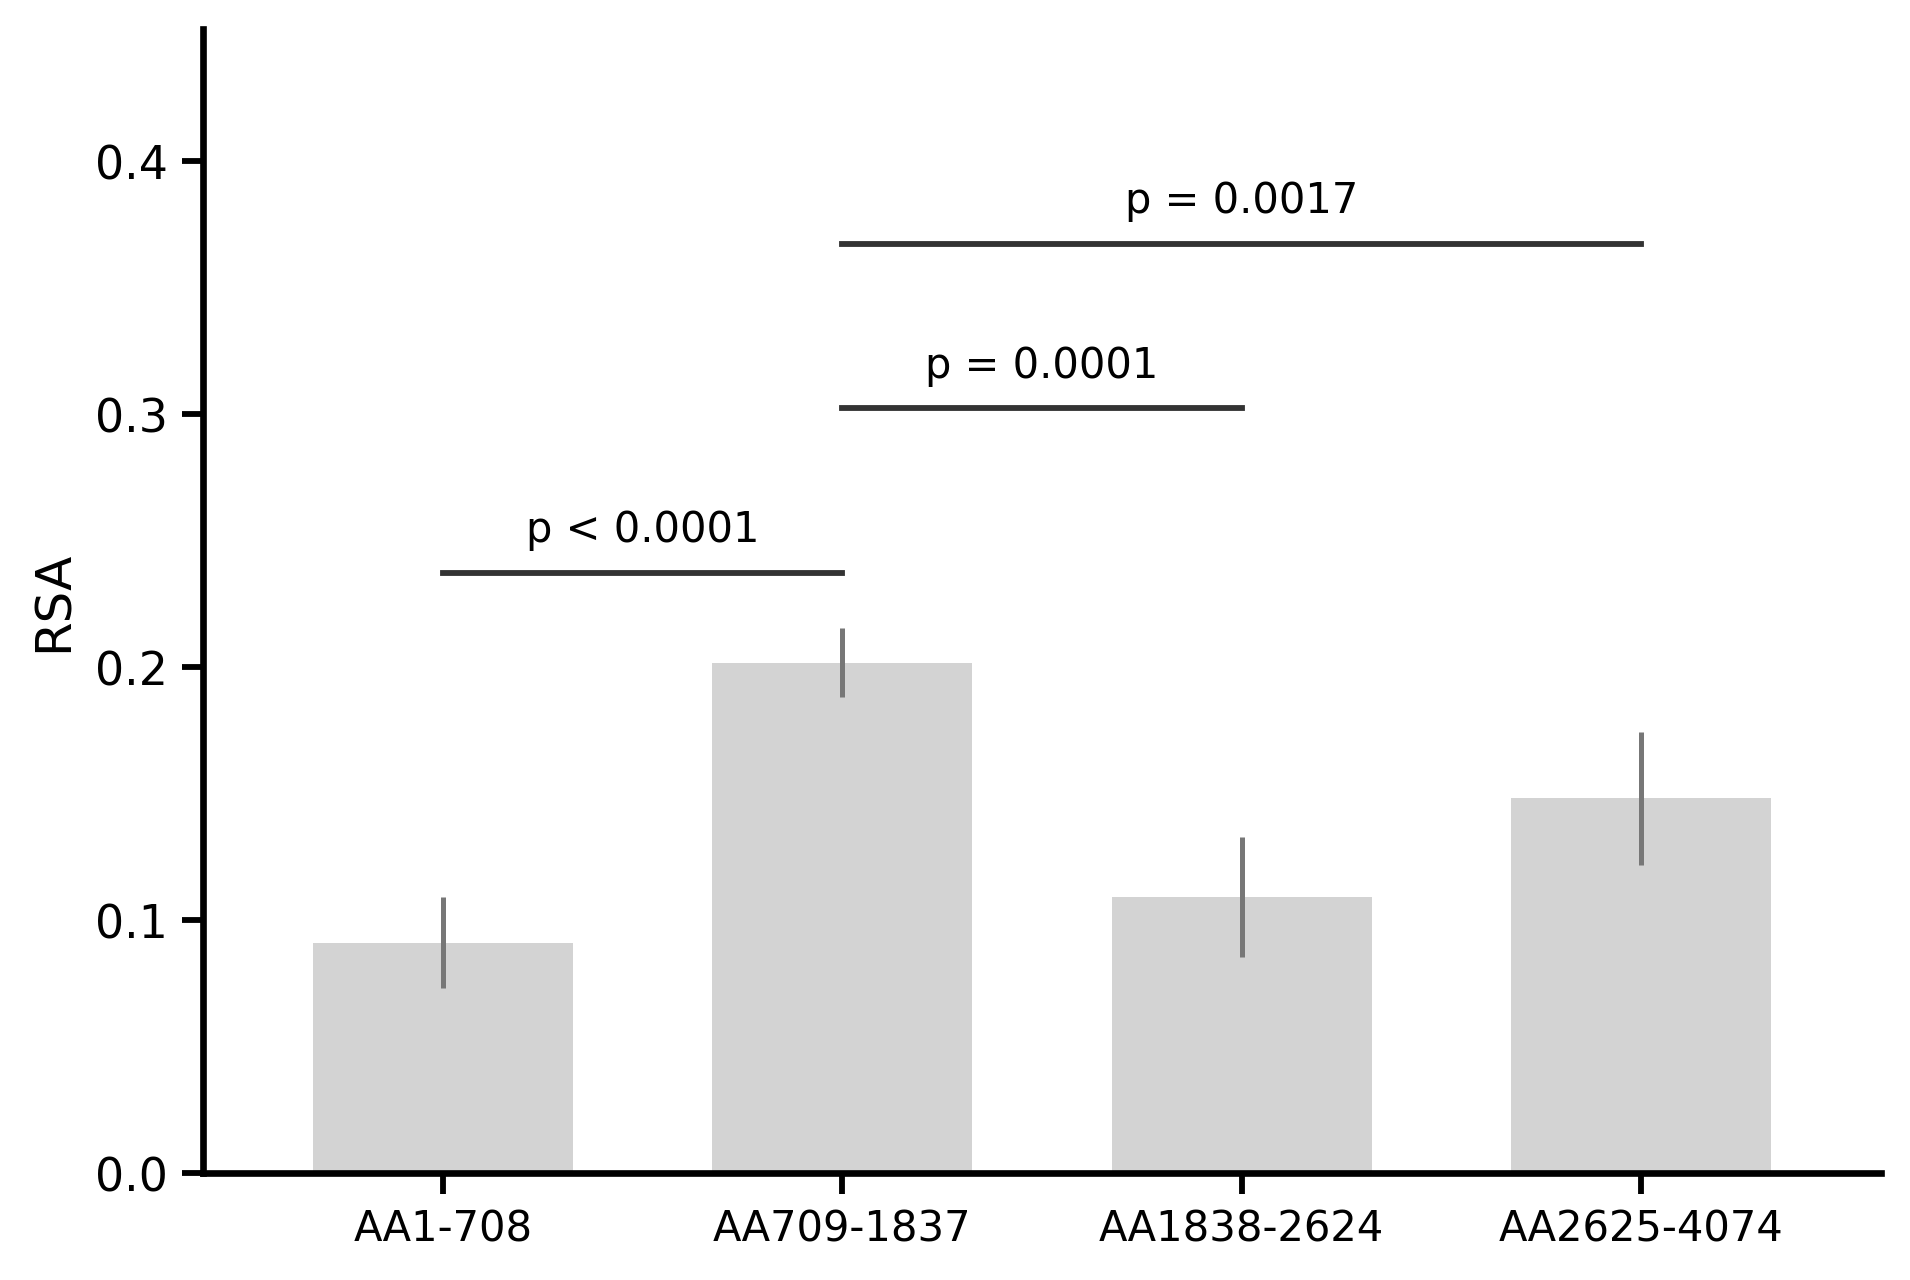


Saved files to: /content/PKHD1_pooled_RSA_patient_level

PATIENT RECORDS REQUIRING REVIEW


,Cohort,CSV row,Group,Genotype,Issue
0,Burgmaier,224,AA1–708,p.Arg124*; p.Leu542Ser; (p.Gly448Arg),"Expected 1 missense allele(s), found 2"


In [12]:

# ============================================================
# PKHD1 POOLED PATIENT-LEVEL RSA ANALYSIS
# Burgmaier + NephVar
#
# Each patient contributes ONE RSA value:
# Missense/Missense = mean of both allele RSA values
# Missense/Null = RSA of the missense allele
#
# Statistics:
# Kruskal-Wallis overall
# Mann-Whitney U pairwise (two-sided)
# Holm correction across all six comparisons
# ============================================================

from pathlib import Path
from itertools import combinations
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display

# ------------------------------------------------------------
# 1. Files and output directory
# ------------------------------------------------------------

RSA_URL = (
    "https://raw.githubusercontent.com/Joshua-Pillai/"
    "PKHD1/main/vus/rsa_output.csv"
)

OUT = Path("/content/PKHD1_pooled_RSA_patient_level")
OUT.mkdir(parents=True, exist_ok=True)

paths = {
    "Burgmaier": Path(
        "/content/Burgmaier_Genotype_Phenotype_Replication - "
        "Burgmaier_S3_Source (2).csv"
    ),
    "NephVar": Path(
        "/content/NephVar Database - PKHD1 (6).csv"
    )
}

if not paths["NephVar"].exists():
    paths["NephVar"] = Path(
        "/content/NephVar Database - PKHD1 (5).csv"
    )

REGIONS = {
    "AA1–708": ("Mis1-708", 1, 708),
    "AA709–1837": ("Mis709-1837", 709, 1837),
    "AA1838–2624": ("Mis1838-2624", 1838, 2624),
    "AA2625–4074": ("Mis2625-4074", 2625, 4074),
}

ORDER = list(REGIONS)

# ------------------------------------------------------------
# 2. Load residue-level RSA
# ------------------------------------------------------------

rsa = pd.read_csv(RSA_URL)
rsa.columns = rsa.columns.str.strip()

assert {"ResNum", "AA", "RSA"}.issubset(rsa.columns)

rsa["ResNum"] = pd.to_numeric(
    rsa["ResNum"], errors="raise"
).astype(int)

rsa["RSA"] = pd.to_numeric(
    rsa["RSA"], errors="coerce"
)

rsa["AA"] = rsa["AA"].str.strip().str.upper()

assert rsa["ResNum"].is_unique

rsa = rsa.set_index("ResNum")

# ------------------------------------------------------------
# 3. Amino acid conversion and missense parser
# ------------------------------------------------------------

AA3 = dict(zip(
    "Ala Arg Asn Asp Cys Gln Glu Gly His Ile Leu Lys "
    "Met Phe Pro Ser Thr Trp Tyr Val".split(),
    "ARNDCQEGHILKMFPSTWYV"
))

AA1 = set(AA3.values())

MISSENSE = re.compile(
    r"(?<![A-Za-z0-9])p\.\(?"
    r"([A-Z][a-z]{2}|[ACDEFGHIKLMNPQRSTVWY])"
    r"(\d+)"
    r"([A-Z][a-z]{2}|[ACDEFGHIKLMNPQRSTVWY])"
    r"\)?(?=$|[\s;,\]\)])"
)

def missense_in_region(text, lo, hi):

    hits = []

    for match in MISSENSE.finditer(str(text)):

        ref, position, alt = match.groups()

        ref = AA3.get(ref, ref)
        alt = AA3.get(alt, alt)
        position = int(position)

        if (
            ref in AA1
            and alt in AA1
            and ref != alt
            and lo <= position <= hi
        ):
            hits.append((ref, position, alt))

    return hits


def get_region_class(value):

    parts = re.sub(
        r"\s+", "", str(value)
    ).split("/")

    if len(parts) != 2:
        return None

    for region, (code, lo, hi) in REGIONS.items():

        if parts in (
            [code, code],
            [code, "Null"],
            ["Null", code]
        ):
            expected = (
                2 if parts == [code, code] else 1
            )

            return region, expected

    return None


# ------------------------------------------------------------
# 4. Calculate RSA for EACH PATIENT
# ------------------------------------------------------------

patient_records = []
audit_records = []

class_counts = {
    group: 0 for group in ORDER
}

for cohort, path in paths.items():

    assert path.exists(), f"Missing CSV: {path}"

    df = pd.read_csv(
        path, dtype=str
    ).fillna("")

    for row_idx, row in df.iterrows():

        assignment = get_region_class(
            row["Functional class"]
        )

        if assignment is None:
            continue

        region, expected_alleles = assignment

        class_counts[region] += 1

        _, lo, hi = REGIONS[region]

        raw = row["Predicted protein change"]

        variants = missense_in_region(
            raw, lo, hi
        )

        # Explicit homozygotes written only once
        if (
            expected_alleles == 2
            and len(variants) == 1
            and re.search(
                r"\bhomozygous\b|\bhomozygote\b|\bhom\.",
                raw,
                re.I
            )
        ):
            variants = variants * 2

        if len(variants) != expected_alleles:

            audit_records.append({
                "Cohort": cohort,
                "CSV row": row_idx + 2,
                "Group": region,
                "Genotype": raw,
                "Issue": (
                    f"Expected {expected_alleles} "
                    f"missense allele(s), found {len(variants)}"
                )
            })

            continue

        rsas = []
        problem = None

        for ref, pos, alt in variants:

            if pos not in rsa.index:
                problem = (
                    f"Residue {pos} absent from RSA table"
                )
                break

            observed_aa = rsa.at[pos, "AA"]
            score = rsa.at[pos, "RSA"]

            if ref != observed_aa:

                problem = (
                    f"Reference mismatch at {pos}: "
                    f"{ref} vs {observed_aa}"
                )
                break

            if not np.isfinite(score):
                problem = f"Missing RSA at {pos}"
                break

            rsas.append(float(score))

        if problem:

            audit_records.append({
                "Cohort": cohort,
                "CSV row": row_idx + 2,
                "Group": region,
                "Genotype": raw,
                "Issue": problem
            })

            continue

        patient_records.append({
            "Cohort": cohort,
            "CSV row": row_idx + 2,
            "Group": region,
            "Genotype": raw,
            "Missense alleles": expected_alleles,
            "Missense variants": "; ".join(
                f"p.{a}{pos}{b}"
                for a, pos, b in variants
            ),
            "RSA allele 1": rsas[0],
            "RSA allele 2": (
                rsas[1] if len(rsas) == 2 else np.nan
            ),
            "Patient RSA": float(np.mean(rsas))
        })


patients_rsa = pd.DataFrame(patient_records)

audit = pd.DataFrame(
    audit_records,
    columns=[
        "Cohort", "CSV row", "Group",
        "Genotype", "Issue"
    ]
)

assert not patients_rsa.empty

print("FOUR-CLASS POOLED PATIENTS")
print("Eligible:", sum(class_counts.values()))
print("Valid RSA:", len(patients_rsa))
print("Flagged:", len(audit))

display(
    pd.crosstab(
        patients_rsa["Group"],
        patients_rsa["Cohort"]
    ).reindex(ORDER).fillna(0).astype(int)
)

# ------------------------------------------------------------
# 5. Descriptive statistics: mean, SEM, median, IQR
# ------------------------------------------------------------

summary = (
    patients_rsa.groupby("Group")["Patient RSA"]
    .agg(
        N="size",
        Mean_RSA="mean",
        SD="std",
        Median_RSA="median",
        Q1=lambda s: s.quantile(0.25),
        Q3=lambda s: s.quantile(0.75)
    )
    .reindex(ORDER)
)

summary["SEM"] = (
    summary["SD"] / np.sqrt(summary["N"])
)

summary["IQR"] = summary["Q3"] - summary["Q1"]

print("\nPATIENT-LEVEL RSA DESCRIPTIVE STATISTICS")
display(summary.round(5))


# ------------------------------------------------------------
# 6. Overall Kruskal-Wallis test
# ------------------------------------------------------------

rsa_groups = {
    group: patients_rsa.loc[
        patients_rsa["Group"] == group,
        "Patient RSA"
    ].dropna().astype(float).to_numpy()
    for group in ORDER
}

H, overall_p = stats.kruskal(
    *(rsa_groups[g] for g in ORDER)
)

print("\nOVERALL KRUSKAL-WALLIS")
print(f"H = {H:.4f}")
print(f"p = {overall_p:.8g}")


# ------------------------------------------------------------
# 7. All six Mann-Whitney U pairwise comparisons
# ------------------------------------------------------------

pairwise_results = []

for group_a, group_b in combinations(ORDER, 2):

    a = rsa_groups[group_a]
    b = rsa_groups[group_b]

    test = stats.mannwhitneyu(
        a,
        b,
        alternative="two-sided",
        method="asymptotic"
    )

    pairwise_results.append({
        "Group 1": group_a,
        "Group 2": group_b,
        "N1": len(a),
        "N2": len(b),
        "U statistic": test.statistic,
        "p_raw": float(test.pvalue)
    })


pairwise = pd.DataFrame(pairwise_results)

# Holm adjustment across all six comparisons
pairwise["p_Holm"] = multipletests(
    pairwise["p_raw"],
    method="holm"
)[1]

pairwise["Significant"] = (
    pairwise["p_Holm"] < 0.05
)

print("\nMANN-WHITNEY U: ALL SIX PAIRWISE COMPARISONS")
display(pairwise.round(7))


# ------------------------------------------------------------
# 8. Publication-style gray RSA bar plot
# Mean ± SEM, with nonparametric test annotations
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.linewidth": 1.6,
    "axes.spines.top": False,
    "axes.spines.right": False
})

fig, ax = plt.subplots(
    figsize=(6.5, 4.4),
    dpi=300
)

x = np.arange(len(ORDER))

means = summary["Mean_RSA"].to_numpy(
    dtype=float
)

sems = summary["SEM"].to_numpy(
    dtype=float
)

ax.bar(
    x,
    means,
    yerr=sems,
    color="#D3D3D3",
    edgecolor="none",
    width=0.65,
    error_kw={
        "ecolor": "#777777",
        "elinewidth": 1.2,
        "capsize": 0
    }
)

ax.set_xticks(x)
ax.set_xticklabels([
    "AA1-708",
    "AA709-1837",
    "AA1838-2624",
    "AA2625-4074"
], fontsize=10)

ax.set_ylabel("RSA", fontsize=12)

ax.set_xlim(-0.6, 3.6)

ax.yaxis.set_major_locator(
    ticker.MultipleLocator(0.1)
)

ax.yaxis.set_major_formatter(
    ticker.FormatStrFormatter("%.1f")
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.6)
ax.spines["bottom"].set_linewidth(1.6)

ax.tick_params(
    direction="out",
    width=1.4,
    length=5
)

ax.grid(False)


# ------------------------------------------------------------
# 9. Pairwise brackets involving AA709-1837
# Display HOLM-ADJUSTED Mann-Whitney p-values
# ------------------------------------------------------------

def get_adjusted_p(group_a, group_b):

    match = pairwise[
        (
            (pairwise["Group 1"] == group_a) &
            (pairwise["Group 2"] == group_b)
        ) |
        (
            (pairwise["Group 1"] == group_b) &
            (pairwise["Group 2"] == group_a)
        )
    ]

    assert len(match) == 1

    return float(match["p_Holm"].iloc[0])


def p_label(p):

    if p < 0.0001:
        return "p < 0.0001"

    return f"p = {p:.4f}"


bracket_pairs = [
    (0, 1),  # AA1-708 vs AA709-1837
    (1, 2),  # AA709-1837 vs AA1838-2624
    (1, 3)   # AA709-1837 vs AA2625-4074
]

base = np.nanmax(means + sems) + 0.022
spacing = 0.065

for j, (i, k) in enumerate(bracket_pairs):

    group_a = ORDER[i]
    group_b = ORDER[k]

    p = get_adjusted_p(
        group_a, group_b
    )

    y = base + spacing * j

    ax.plot(
        [i, k],
        [y, y],
        color="#333333",
        linewidth=1.4
    )

    ax.text(
        (i + k) / 2,
        y + 0.009,
        p_label(p),
        ha="center",
        va="bottom",
        fontsize=10
    )


ax.set_ylim(
    0,
    max(
        0.4,
        base + spacing * len(bracket_pairs) + 0.02
    )
)

fig.tight_layout()


# ------------------------------------------------------------
# 10. Save results
# ------------------------------------------------------------

fig.savefig(
    OUT / "pooled_patient_RSA_MannWhitney.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)

fig.savefig(
    OUT / "pooled_patient_RSA_MannWhitney.pdf",
    transparent=True,
    bbox_inches="tight"
)

plt.show()

patients_rsa.to_csv(
    OUT / "pooled_RSA_per_patient.csv",
    index=False
)

summary.to_csv(
    OUT / "pooled_RSA_summary.csv"
)

pairwise.to_csv(
    OUT / "pooled_RSA_MannWhitney_pairwise.csv",
    index=False
)

audit.to_csv(
    OUT / "pooled_RSA_mapping_audit.csv",
    index=False
)

print("\nSaved files to:", OUT)

if len(audit):

    print("\nPATIENT RECORDS REQUIRING REVIEW")
    display(audit)
